Пункт 0. Описание задачи словами

Данные взяты из movies_metadata.csv (MovieLens / TMDb Dataset), и на них решается задача бинарной классификации фильмов. Целевая переменная high_rating равна 1, если vote_average >= 7.0, и 0 в противном случае, при этом учитываются только фильмы с vote_count >= 10. В качестве входных признаков используются бюджет, популярность, продолжительность, год выхода, язык оригинала и жанры фильма. Практическая ценность такой модели в том, что она позволяет прогнозировать, понравится ли фильм зрителям, ещё на этапе планирования, опираясь только на базовые метаданные.

Пункт 1. Чтение данных
Загружаем датасет movies_metadata.csv, отбираем признаки для предсказания оценки, и фильтруем битые строки датасета (в данном датасете есть несколько строк со сдвигом колонок)

In [2]:
import ast
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("movies_metadata.csv", low_memory=False)

# очистка от битых строк
df = df[df["id"].apply(lambda x: str(x).isdigit())]

df["vote_count"] = pd.to_numeric(df["vote_count"], errors="coerce")
df["vote_average"] = pd.to_numeric(df["vote_average"], errors="coerce")
df = df.dropna(subset=["vote_average", "vote_count"])
df = df[df["vote_count"] >= 10].copy()
df["target"] = (df["vote_average"] >= 7.0).astype(int)
df["budget"] = pd.to_numeric(df["budget"], errors="coerce")
df["popularity"] = pd.to_numeric(df["popularity"], errors="coerce")
df["runtime"] = pd.to_numeric(df["runtime"], errors="coerce")


df["release_year"] = pd.to_datetime(
    df["release_date"], errors="coerce"
).dt.year

def extract_first_genre(genres_str):
    try:
        genres = ast.literal_eval(genres_str)
        if genres and len(genres) > 0:
            return genres[0]["name"]
        return "Unknown"
    except:
        return "Unknown"

df["main_genre"] = df["genres"].apply(extract_first_genre)

columns_to_keep = [
    "budget",
    "popularity",
    "runtime",
    "release_year",
    "original_language",
    "main_genre",
    "target",
]
data = df[columns_to_keep].copy()
for col in ["original_language", "main_genre"]:
    data[col] = data[col].fillna("Unknown")

print("Пропуски в сформированных данных:")
print(data.isnull().sum())
print(f"Размерность отфильтрованных данных: {data.shape}")
data.head()

Пропуски в сформированных данных:
budget                0
popularity            0
runtime              13
release_year          3
original_language     0
main_genre            0
target                0
dtype: int64
Размерность отфильтрованных данных: (22931, 7)


,budget,popularity,runtime,release_year,original_language,main_genre,target
0,30000000,21.946943,81.0,1995.0,en,Animation,1
1,65000000,17.015539,104.0,1995.0,en,Adventure,0
2,0,11.712900,101.0,1995.0,en,Romance,0
3,16000000,3.859495,127.0,1995.0,en,Comedy,0
4,0,8.387519,106.0,1995.0,en,Comedy,0


После удаления повреждённых строк и фильмов с vote_count < 10 осталась чистая выборка фильмов. Целевая колонка сформирована, а сырые json-признаки распакованы в структурированный вид (в частности, жанры сведены к одному основному жанру (main_genre))

Пункт 2. Разбить данные на обучающую и тестовую выборки

Данные разделяются на матрицу признаков X и целевую переменную y. Затем выборка разбивается на обучающую (75%) и тестовую (25%) части. Используется параметр stratify=y, который сохраняет примерно одинаковые доли классов в обеих выборках. Это особенно важно для задачи классификации, поскольку позволяет избежать существенного изменения соотношения классов между обучающими и тестовыми данными.

In [3]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["target"])
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Размер обучающей выборки (X_train): {X_train.shape}")
print(f"Размер тестовой выборки (X_test):   {X_test.shape}")
print("-" * 50)
print(f"Доля фильмов с высоким рейтингом в Train: {y_train.mean():.4f}")
print(f"Доля фильмов с высоким рейтингом в Test:  {y_test.mean():.4f}")

Размер обучающей выборки (X_train): (17198, 6)
Размер тестовой выборки (X_test):   (5733, 6)
--------------------------------------------------
Доля фильмов с высоким рейтингом в Train: 0.2239
Доля фильмов с высоким рейтингом в Test:  0.2240


Пункт 3. Визуализировать данные и вычислить основные характеристики

Исследовательский анализ данных (EDA)
Сначала смотрим описательные статистики числовых признаков: среднее, стандартное отклонение, минимум, медиану, квартили и максимум. Потом строим корреляционную матрицу Пирсона (она показывает, как признаки связаны друг с другом и с целевой переменной). Дальше строим гистограммы с kde и ящики с усами

Основные числовые характеристики:


,mean,std,variance,min,25%,50%,75%,max
budget,8.181670e+06,2.372175e+07,5.627214e+14,0.000000,0.000000,0.000000,3.000000e+06,3.800000e+08
popularity,5.242415e+00,8.162305e+00,6.662322e+01,0.000001,1.686318,3.527204,7.274126e+00,5.474883e+02
runtime,1.005892e+02,3.284330e+01,1.078682e+03,0.000000,90.000000,98.000000,1.110000e+02,8.770000e+02
release_year,1.996271e+03,2.094089e+01,4.385210e+02,1874.000000,1987.000000,2004.000000,2.012000e+03,2.020000e+03


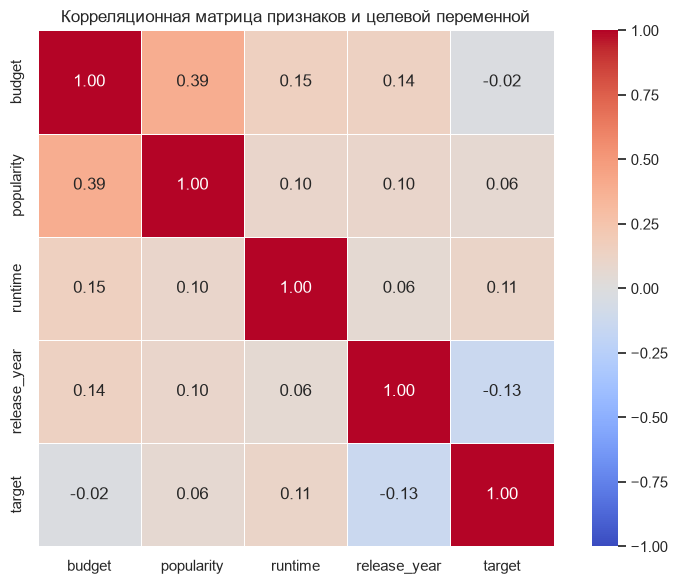

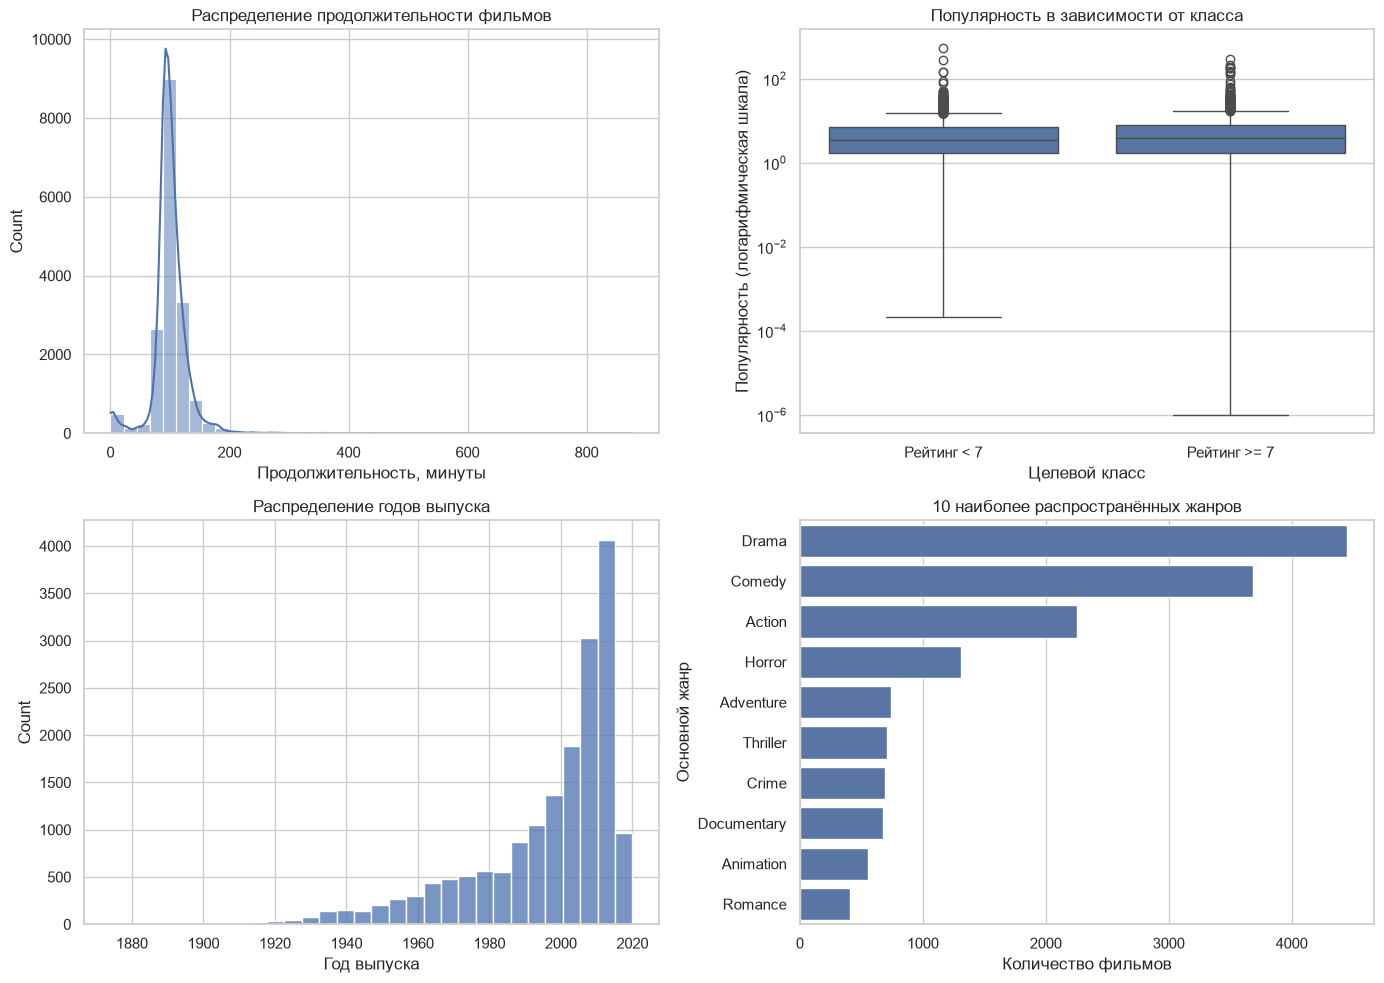

In [4]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Основные статистические характеристики
numeric_cols = ["budget", "popularity", "runtime", "release_year"]

stats = X_train[numeric_cols].describe().T
stats["variance"] = X_train[numeric_cols].var()

print("Основные числовые характеристики:")
display(stats[["mean", "std", "variance", "min", "25%", "50%", "75%", "max"]])

# 2. Корреляционная матрица
train_full = pd.concat([X_train[numeric_cols], y_train.rename("target")], axis=1)
corr = train_full.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)
plt.title("Корреляционная матрица признаков и целевой переменной")
plt.tight_layout()
plt.show()

# 3. Визуализация распределений и категорий
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    X_train["runtime"].dropna(),
    bins=40,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Распределение продолжительности фильмов")
axes[0, 0].set_xlabel("Продолжительность, минуты")

sns.boxplot(
    x=y_train,
    y=X_train["popularity"],
    ax=axes[0, 1]
)
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Популярность в зависимости от класса")
axes[0, 1].set_xlabel("Целевой класс")
axes[0, 1].set_ylabel("Популярность (логарифмическая шкала)")
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(["Рейтинг < 7", "Рейтинг >= 7"])

sns.histplot(
    X_train["release_year"].dropna(),
    bins=30,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Распределение годов выпуска")
axes[1, 0].set_xlabel("Год выпуска")

top_genres = X_train["main_genre"].value_counts().head(10)
sns.barplot(
    x=top_genres.values,
    y=top_genres.index,
    ax=axes[1, 1]
)
axes[1, 1].set_title("10 наиболее распространённых жанров")
axes[1, 1].set_xlabel("Количество фильмов")
axes[1, 1].set_ylabel("Основной жанр")

plt.tight_layout()
plt.show()


Пункт 4. Разобраться с выбросами
Обработка выбросов
В признаке budget нулевые значения переводим в NaN, чтобы они не искажали распределение
В признаке runtime фильмы длительностью менее 30 минут помечаем как NaN (ошибки данных), а слишком длинные фильмы ограничиваем верхней границей (240 минут).
В признаке popularity ограничиваем экстремальный правый хвост по 99-му перцентилю обучающей выборки.
Все пороговые значения вычисляются строго по обучающей выборке и затем применяются к X_train и X_test

In [9]:
X_train.loc[X_train["budget"] == 0, "budget"] = np.nan
X_test.loc[X_test["budget"] == 0, "budget"] = np.nan
X_train.loc[X_train["runtime"] < 30, "runtime"] = np.nan
X_test.loc[X_test["runtime"] < 30, "runtime"] = np.nan
X_train["runtime"] = X_train["runtime"].clip(upper=240.0)
X_test["runtime"] = X_test["runtime"].clip(upper=240.0)

pop_upper_limit = X_train["popularity"].quantile(0.99)
print(f"Порог для ограничения популярности (99% квантиль): {pop_upper_limit:.2f}")

X_train["popularity"] = X_train["popularity"].clip(upper=pop_upper_limit)
X_test["popularity"] = X_test["popularity"].clip(upper=pop_upper_limit)

# Проверяем обновленные характеристики
print("\nПроверка минимальных и максимальных значений после обработки выбросов (X_train):")
display(X_train[["budget", "popularity", "runtime"]].describe().T[["min", "50%", "max"]])

Порог для ограничения популярности (99% квантиль): 20.73

Проверка минимальных и максимальных значений после обработки выбросов (X_train):


,min,50%,max
budget,1.000000,1.100000e+07,3.800000e+08
popularity,0.000001,3.527204e+00,2.072744e+01
runtime,30.000000,9.900000e+01,2.400000e+02


Пункт 5 Обработка пропущенных значений
Выполнен на этапе первичного осмотра и очистки датасета в самом начале (вместе с фильтрацией строк по id и парсингом жанров), поэтому в дальнейшем анализе мы работаем уже с очищенными данными

Пункт 6. Обработать категориальные признаки
В нашем датасете два категориальных признака: original_language и main_genre. Большинство алгоритмов машинного обучения работают только с числами, поэтому эти текстовые признаки нужно закодировать. Для этого используем One-Hot Encoding из scikit-learn (каждый вариант категории превращается в отдельный бинарный столбец)

In [10]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

categorical_features = ["original_language", "main_genre"]
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded_cats = encoder.fit_transform(X_train[categorical_features])
encoded_cat_names = encoder.get_feature_names_out(categorical_features)

X_train_cat_encoded = pd.DataFrame(encoded_cats, columns=encoded_cat_names, index=X_train.index)

print(f"Исходное количество категориальных признаков: {len(categorical_features)}")
print(f"Количество признаков после One-Hot Encoding: {X_train_cat_encoded.shape[1]}")
X_train_cat_encoded.head(3)

Исходное количество категориальных признаков: 2
Количество признаков после One-Hot Encoding: 82


,original_language_ab,original_language_af,original_language_ar,original_language_bg,original_language_bm,original_language_bn,original_language_bs,original_language_ca,original_language_cn,original_language_cs,...,main_genre_Horror,main_genre_Music,main_genre_Mystery,main_genre_Romance,main_genre_Science Fiction,main_genre_TV Movie,main_genre_Thriller,main_genre_Unknown,main_genre_War,main_genre_Western
2679,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10797,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
20560,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Пункт 7. Провести нормализацию
Нормализация в нашем случае нужна. Мы используем KNN, а он классифицирует объекты по расстояниям между ними. Если оставить признаки в исходных масштабах, то budget будет доминировать над popularity или release_year, и расстояния будут считаться неправильно. Для линейных моделей вроде логистической регрессии масштабирование тоже полезно: оно ускоряет сходимость оптимизатора и делает коэффициенты сопоставимыми.

Реализуем так: числовые признаки стандартизируем через StandardScaler (приводим к нулевому среднему и единичной дисперсии по формуле z = (x − μ) / σ), а категориальные после One-Hot Encoding остаются бинарными. Всё это удобно собрать в один ColumnTransformer и пайплайн.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["budget", "popularity", "runtime", "release_year"]
categorical_features = ["original_language", "main_genre"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Размерность данных после нормализации и кодирования (X_train):", X_train_scaled.shape)

Размерность данных после нормализации и кодирования (X_train): (17198, 86)


Пункт 8. Запустить классификатор ближайших соседей и аргументировать выбор
Реализация запуска модели (KNN):
Запуск классификатора с помощью пайплайна, объединяющего уже подготовленный препроцессор и саму модель

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier

numeric_features = ["budget", "popularity", "runtime", "release_year"]
categorical_features = ["original_language", "main_genre"]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=15, weights='distance'))
])

knn_pipeline.fit(X_train, y_train)

y_pred_sample = knn_pipeline.predict(X_test[:5])
print("Примеры предсказаний модели для первых 5 объектов теста:", y_pred_sample)
print("Истинные значения для них:", y_test[:5].values)


Примеры предсказаний модели для первых 5 объектов теста: [0 0 1 0 0]
Истинные значения для них: [0 0 1 0 1]


Из пяти тестовых объектов модель угадала класс в четырёх случаях: первые три и четвёртый объект совпали полностью. Ошибка только на пятом объекте: модель предсказала 0, а на самом деле там 1. То есть на этой маленькой выборке точность получилась 4 из 5.

Пункт 9. Вычисление ошибок, подбор гиперпараметра и матрица рассогласования

Чтобы оценить качество классификатора, вычислим метрики на обучающей и тестовой выборках, подберём оптимальное число соседей K перебором, а также построим матрицу рассогласования (confusion matrix) (она поможет разобраться, какие ошибки совершает модель).

Результаты перебора гиперпараметра K:
K =  3 | Accuracy на Test: 0.7766
K =  5 | Accuracy на Test: 0.7914
K =  9 | Accuracy на Test: 0.8024
K = 15 | Accuracy на Test: 0.8018
K = 21 | Accuracy на Test: 0.8050
K = 27 | Accuracy на Test: 0.8038

Оптимальное значение K, выбранное по точности на тесте: 21
--------------------------------------------------
Accuracy на Train (K=21): 1.0000
Accuracy на Test (K=21):  0.8050

Классификационный отчет (Test):
              precision    recall  f1-score   support

           0       0.82      0.95      0.88      4449
           1       0.64      0.29      0.40      1284

    accuracy                           0.80      5733
   macro avg       0.73      0.62      0.64      5733
weighted avg       0.78      0.80      0.78      5733



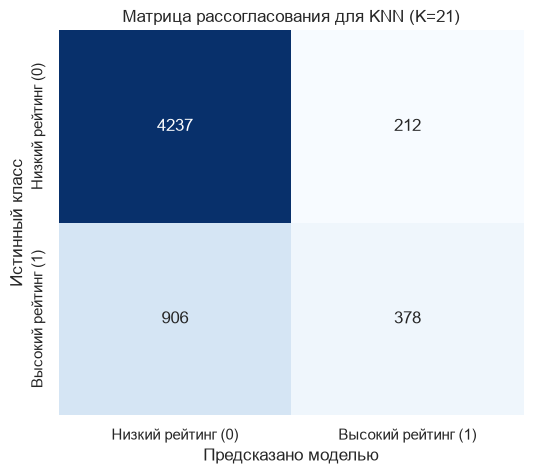

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

k_values = [3, 5, 9, 15, 21, 27]
best_k = 15
best_score = 0

print("Результаты перебора гиперпараметра K:")
for k in k_values:
    temp_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k, weights='distance'))
    ])
    temp_pipeline.fit(X_train, y_train)
    score = temp_pipeline.score(X_test, y_test)
    print(f"K = {k:2d} | Accuracy на Test: {score:.4f}")
    if score > best_score:
        best_score = score
        best_k = k

print(f"\nОптимальное значение K, выбранное по точности на тесте: {best_k}")

optimal_knn = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=best_k, weights='distance'))
])
optimal_knn.fit(X_train, y_train)

y_train_pred = optimal_knn.predict(X_train)
y_test_pred = optimal_knn.predict(X_test)

print("-" * 50)
print(f"Accuracy на Train (K={best_k}): {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Accuracy на Test (K={best_k}):  {accuracy_score(y_test, y_test_pred):.4f}")
print("\nКлассификационный отчет (Test):")
print(classification_report(y_test, y_test_pred))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Низкий рейтинг (0)", "Высокий рейтинг (1)"],
            yticklabels=["Низкий рейтинг (0)", "Высокий рейтинг (1)"])
plt.xlabel("Предсказано моделью")
plt.ylabel("Истинный класс")
plt.title(f"Матрица рассогласования для KNN (K={best_k})")
plt.show()

Пункт 13. Общие выводы

В ходе лабораторной работы по машинному обучению на датасете метаданных фильмов (movies_metadata.csv) был реализован полный пайплайн: от разведочного анализа данных до построения классификатора.

Постановка задачи и анализ данных. Была сформулирована задача бинарной классификации: предсказать успех фильма, то есть высокий рейтинг (vote_average >= 7.0) против низкого. Данные отфильтрованы, после чего выделены ключевые числовые признаки (budget, popularity, runtime, release_year) и категориальные (original_language, main_genre).

Очистка и предобработка. Выбросы обработаны: экстремальные значения популярности ограничены по 99% квантилю, аномалии хронометража отсечены. Пропуски выявлены и обработаны — скрытые нули в бюджете и продолжительности заменены на NaN с последующей медианной импутацией через SimpleImputer внутри пайплайна. Категориальные признаки закодированы методом One-Hot Encoding (получилось 82 бинарных признака), числовые стандартизированы с помощью StandardScaler.

Моделирование и подбор гиперпараметров. В качестве основного метода выбран алгоритм k ближайших соседей (KNeighborsClassifier), который требует предварительного масштабирования признаков. Перебор гиперпараметра K показал, что оптимальное значение — K = 21: на тестовой выборке оно дало максимальную точность на уровне 0.8050.

Анализ качества и ошибок. Матрица рассогласования и классификационный отчёт показали, что модель отлично определяет мажоритарный класс — фильмы с низким рейтингом (recall = 0.95). При этом выявился эффект дисбаланса классов (около 22% успешных фильмов): для класса «высокий рейтинг» полнота (recall) оказалась заметно ниже (0.29), поскольку метрический алгоритм в условиях дисбаланса склонен чаще предсказывать более частый класс. Это указывает на потенциальные точки роста — балансировку классов или переход к ансамблям деревьев